<a href="https://colab.research.google.com/github/pratham-347/semiconductor-defect-prediction/blob/main/notebooks/01_secom_data_understanding.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [6]:
from google.colab import files

# Prompt to upload secom.data, secom.names, and secom_labels.data
uploaded = files.upload()

for fn in uploaded.keys():
  print('User uploaded file "{name}" with length {length} bytes'.format(
      name=fn, length=len(uploaded[fn])))

Saving secom.data to secom.data
Saving secom.names to secom.names
Saving secom_labels.data to secom_labels.data
User uploaded file "secom.data" with length 5389983 bytes
User uploaded file "secom.names" with length 4223 bytes
User uploaded file "secom_labels.data" with length 40638 bytes


In [7]:
import os

print(os.listdir("/content"))

['.config', 'secom.data', 'secom.names', 'secom_labels.data', 'sample_data']


In [8]:
import os

required_files = [
    "secom.data",
    "secom_labels.data",
    "secom.names"
]

for file in required_files:
    if os.path.exists(f"/content/{file}"):
        print(f"FOUND: {file}")
    else:
        print(f"MISSING: {file}")

FOUND: secom.data
FOUND: secom_labels.data
FOUND: secom.names


In [9]:
import pandas as pd

# Load manufacturing measurements
X = pd.read_csv(
    "/content/secom.data",
    sep=r"\s+",
    header=None
)

# Load inspection labels
y = pd.read_csv(
    "/content/secom_labels.data",
    sep=r"\s+",
    header=None
)

# Extract the target label
y = y.iloc[:, 0]

# Combine measurements and labels
df = X.copy()
df["target"] = y

print("Dataset loaded successfully!")
print("Shape:", df.shape)

df.head()

Dataset loaded successfully!
Shape: (1567, 591)


,0,1,2,3,4,5,6,7,8,9,...,581,582,583,584,585,586,587,588,589,target
0,3030.93,2564.00,2187.7333,1411.1265,1.3602,100.0,97.6133,0.1242,1.5005,0.0162,...,NaN,0.5005,0.0118,0.0035,2.3630,NaN,NaN,NaN,NaN,-1
1,3095.78,2465.14,2230.4222,1463.6606,0.8294,100.0,102.3433,0.1247,1.4966,-0.0005,...,208.2045,0.5019,0.0223,0.0055,4.4447,0.0096,0.0201,0.0060,208.2045,-1
2,2932.61,2559.94,2186.4111,1698.0172,1.5102,100.0,95.4878,0.1241,1.4436,0.0041,...,82.8602,0.4958,0.0157,0.0039,3.1745,0.0584,0.0484,0.0148,82.8602,1
3,2988.72,2479.90,2199.0333,909.7926,1.3204,100.0,104.2367,0.1217,1.4882,-0.0124,...,73.8432,0.4990,0.0103,0.0025,2.0544,0.0202,0.0149,0.0044,73.8432,-1
4,3032.24,2502.87,2233.3667,1326.5200,1.5334,100.0,100.3967,0.1235,1.5031,-0.0031,...,NaN,0.4800,0.4766,0.1045,99.3032,0.0202,0.0149,0.0044,73.8432,-1


In [10]:
# Display first 5 records
display(df.head())

# Display last 5 records
display(df.tail())

# Check column names and data types
df.info()

# Check target values
print("\nTarget values:")
print(df["target"].value_counts())

,0,1,2,3,4,5,6,7,8,9,...,581,582,583,584,585,586,587,588,589,target
0,3030.93,2564.00,2187.7333,1411.1265,1.3602,100.0,97.6133,0.1242,1.5005,0.0162,...,NaN,0.5005,0.0118,0.0035,2.3630,NaN,NaN,NaN,NaN,-1
1,3095.78,2465.14,2230.4222,1463.6606,0.8294,100.0,102.3433,0.1247,1.4966,-0.0005,...,208.2045,0.5019,0.0223,0.0055,4.4447,0.0096,0.0201,0.0060,208.2045,-1
2,2932.61,2559.94,2186.4111,1698.0172,1.5102,100.0,95.4878,0.1241,1.4436,0.0041,...,82.8602,0.4958,0.0157,0.0039,3.1745,0.0584,0.0484,0.0148,82.8602,1
3,2988.72,2479.90,2199.0333,909.7926,1.3204,100.0,104.2367,0.1217,1.4882,-0.0124,...,73.8432,0.4990,0.0103,0.0025,2.0544,0.0202,0.0149,0.0044,73.8432,-1
4,3032.24,2502.87,2233.3667,1326.5200,1.5334,100.0,100.3967,0.1235,1.5031,-0.0031,...,NaN,0.4800,0.4766,0.1045,99.3032,0.0202,0.0149,0.0044,73.8432,-1


,0,1,2,3,4,5,6,7,8,9,...,581,582,583,584,585,586,587,588,589,target
1562,2899.41,2464.36,2179.7333,3085.3781,1.4843,100.0,82.2467,0.1248,1.3424,-0.0045,...,203.1720,0.4988,0.0143,0.0039,2.8669,0.0068,0.0138,0.0047,203.1720,-1
1563,3052.31,2522.55,2198.5667,1124.6595,0.8763,100.0,98.4689,0.1205,1.4333,-0.0061,...,NaN,0.4975,0.0131,0.0036,2.6238,0.0068,0.0138,0.0047,203.1720,-1
1564,2978.81,2379.78,2206.3000,1110.4967,0.8236,100.0,99.4122,0.1208,NaN,NaN,...,43.5231,0.4987,0.0153,0.0041,3.0590,0.0197,0.0086,0.0025,43.5231,-1
1565,2894.92,2532.01,2177.0333,1183.7287,1.5726,100.0,98.7978,0.1213,1.4622,-0.0072,...,93.4941,0.5004,0.0178,0.0038,3.5662,0.0262,0.0245,0.0075,93.4941,-1
1566,2944.92,2450.76,2195.4444,2914.1792,1.5978,100.0,85.1011,0.1235,NaN,NaN,...,137.7844,0.4987,0.0181,0.0040,3.6275,0.0117,0.0162,0.0045,137.7844,-1


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1567 entries, 0 to 1566
Columns: 591 entries, 0 to target
dtypes: float64(590), int64(1)
memory usage: 7.1 MB

Target values:
target
-1    1463
 1     104
Name: count, dtype: int64


In [11]:
# Count missing values in the entire dataset
total_missing = df.isnull().sum().sum()

print("Total missing values:", total_missing)

# Missing values in each feature
missing_per_column = df.drop(columns=["target"]).isnull().sum()

# Features containing missing values
missing_features = missing_per_column[
    missing_per_column > 0
]

print("Features containing missing values:",
      len(missing_features))

# Display 15 features with the most missing values
print("\nTop 15 features with missing values:")
print(missing_features.sort_values(ascending=False).head(15))

Total missing values: 41951
Features containing missing values: 538

Top 15 features with missing values:
292    1429
157    1429
158    1429
293    1429
492    1341
220    1341
358    1341
85     1341
516    1018
517    1018
382    1018
111    1018
383    1018
384    1018
246    1018
dtype: int64


In [12]:
# Calculate missing percentage for every feature
missing_percentage = (
    df.drop(columns=["target"]).isnull().mean() * 100
)

# Create a summary table
missing_summary = pd.DataFrame({
    "Missing_Count": missing_per_column,
    "Missing_Percentage": missing_percentage
})

# Sort from most missing to least missing
missing_summary = missing_summary.sort_values(
    by="Missing_Percentage",
    ascending=False
)

print("Top 20 features by missing percentage:")
display(missing_summary.head(20))

# Count features crossing different missingness thresholds
print("\nFeatures with more than 50% missing:",
      (missing_percentage > 50).sum())

print("Features with more than 80% missing:",
      (missing_percentage > 80).sum())

print("Features with more than 90% missing:",
      (missing_percentage > 90).sum())

# Overall missing percentage
overall_missing = (
    df.drop(columns=["target"]).isnull().sum().sum()
    / (1567 * 590)
) * 100

print("\nOverall missing percentage:", round(overall_missing, 2), "%")

Top 20 features by missing percentage:


,Missing_Count,Missing_Percentage
292,1429,91.193363
293,1429,91.193363
158,1429,91.193363
157,1429,91.193363
492,1341,85.577537
85,1341,85.577537
358,1341,85.577537
220,1341,85.577537
244,1018,64.964901
517,1018,64.964901



Features with more than 50% missing: 28
Features with more than 80% missing: 8
Features with more than 90% missing: 4

Overall missing percentage: 4.54 %


In [13]:
from sklearn.model_selection import train_test_split

# Separate input features and target
X = df.drop(columns=["target"])
y = df["target"]

# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Display dataset sizes
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

# Check class distribution
print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

Training features: (1253, 590)
Testing features: (314, 590)

Training target distribution:
target
-1    1170
 1      83
Name: count, dtype: int64

Testing target distribution:
target
-1    293
 1     21
Name: count, dtype: int64


In [14]:
# Calculate missing percentage using training data only
train_missing_percentage = X_train.isnull().mean() * 100

# Identify features with more than 80% missing values
columns_to_drop = train_missing_percentage[
    train_missing_percentage > 80
].index

print("Number of features to remove:", len(columns_to_drop))
print("Feature indices:", list(columns_to_drop))

# Remove the same features from training and testing data
X_train_reduced = X_train.drop(columns=columns_to_drop)
X_test_reduced = X_test.drop(columns=columns_to_drop)

# Verify new dimensions
print("\nTraining shape:", X_train_reduced.shape)
print("Testing shape:", X_test_reduced.shape)

Number of features to remove: 8
Feature indices: [85, 157, 158, 220, 292, 293, 358, 492]

Training shape: (1253, 582)
Testing shape: (314, 582)


In [15]:
from sklearn.impute import SimpleImputer

# Create median imputer
imputer = SimpleImputer(strategy="median")

# Learn median values from training data and transform it
X_train_imputed = imputer.fit_transform(X_train_reduced)

# Use the same learned median values on testing data
X_test_imputed = imputer.transform(X_test_reduced)

# Convert back to DataFrames
X_train_imputed = pd.DataFrame(
    X_train_imputed,
    columns=X_train_reduced.columns,
    index=X_train_reduced.index
)

X_test_imputed = pd.DataFrame(
    X_test_imputed,
    columns=X_test_reduced.columns,
    index=X_test_reduced.index
)

# Verify missing values
print("Missing values in training:",
      X_train_imputed.isnull().sum().sum())

print("Missing values in testing:",
      X_test_imputed.isnull().sum().sum())

print("\nTraining shape:", X_train_imputed.shape)
print("Testing shape:", X_test_imputed.shape)

Missing values in training: 0
Missing values in testing: 0

Training shape: (1253, 582)
Testing shape: (314, 582)


In [16]:
import numpy as np

# Check infinite values
print("Infinite values in training:",
      np.isinf(X_train_imputed.to_numpy()).sum())

print("Infinite values in testing:",
      np.isinf(X_test_imputed.to_numpy()).sum())

# Identify constant features using training data
constant_features = X_train_imputed.columns[
    X_train_imputed.nunique() <= 1
]

print("\nConstant features:", len(constant_features))
print("Constant feature indices:", list(constant_features))

# Check whether train and test columns match
print("\nColumns match:",
      list(X_train_imputed.columns) ==
      list(X_test_imputed.columns))

Infinite values in training: 0
Infinite values in testing: 0

Constant features: 116
Constant feature indices: [5, 13, 42, 49, 52, 69, 97, 141, 149, 178, 179, 186, 189, 190, 191, 192, 193, 194, 226, 229, 230, 231, 232, 233, 234, 235, 236, 237, 240, 241, 242, 243, 256, 257, 258, 259, 260, 261, 262, 263, 264, 265, 266, 276, 284, 313, 314, 315, 322, 325, 326, 327, 328, 329, 330, 364, 369, 370, 371, 372, 373, 374, 375, 378, 379, 380, 381, 394, 395, 396, 397, 398, 399, 400, 401, 402, 403, 404, 414, 422, 449, 450, 451, 458, 461, 462, 463, 464, 465, 466, 481, 498, 501, 502, 503, 504, 505, 506, 507, 508, 509, 512, 513, 514, 515, 528, 529, 530, 531, 532, 533, 534, 535, 536, 537, 538]

Columns match: True


In [18]:
# Identify constant features from training data
constant_features = X_train_imputed.columns[
    X_train_imputed.nunique() <= 1
]

# Remove them from both datasets
X_train_clean = X_train_imputed.drop(columns=constant_features)
X_test_clean = X_test_imputed.drop(columns=constant_features)

print("Features before removal:", X_train_imputed.shape[1])
print("Constant features removed:", len(constant_features))
print("Features after removal:", X_train_clean.shape[1])

print("\nFinal training shape:", X_train_clean.shape)
print("Final testing shape:", X_test_clean.shape)

print("\nColumns match:",
      list(X_train_clean.columns) == list(X_test_clean.columns))

Features before removal: 582
Constant features removed: 116
Features after removal: 466

Final training shape: (1253, 466)
Final testing shape: (314, 466)

Columns match: True


In [19]:
from sklearn.preprocessing import StandardScaler

# Create the scaler
scaler = StandardScaler()

# Learn scaling parameters from training data only
X_train_scaled = scaler.fit_transform(X_train_clean)

# Apply the same parameters to test data
X_test_scaled = scaler.transform(X_test_clean)

print("Training shape:", X_train_scaled.shape)
print("Testing shape:", X_test_scaled.shape)

print("\nMean of first 5 scaled features:")
print(X_train_scaled.mean(axis=0)[:5])

print("\nStandard deviation of first 5 scaled features:")
print(X_train_scaled.std(axis=0)[:5])

Training shape: (1253, 466)
Testing shape: (314, 466)

Mean of first 5 scaled features:
[-7.83836949e-15 -5.04695159e-16  1.09785374e-14  3.33155513e-16
 -2.83536606e-18]

Standard deviation of first 5 scaled features:
[1. 1. 1. 1. 1.]


In [20]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

# Model 1: Dummy Classifier
dummy_model = DummyClassifier(strategy="most_frequent")
dummy_model.fit(X_train_scaled, y_train)

dummy_predictions = dummy_model.predict(X_test_scaled)

# Model 2: Logistic Regression
logistic_model = LogisticRegression(
    class_weight="balanced",
    max_iter=3000,
    random_state=42
)

logistic_model.fit(X_train_scaled, y_train)

logistic_predictions = logistic_model.predict(X_test_scaled)

# Evaluation function
def evaluate_model(name, y_true, predictions, probabilities=None):
    print(f"\n{'=' * 45}")
    print(name)
    print("=" * 45)

    print("Accuracy:", round(accuracy_score(y_true, predictions), 4))
    print("Precision:", round(precision_score(y_true, predictions, pos_label=1, zero_division=0), 4))
    print("Recall:", round(recall_score(y_true, predictions, pos_label=1, zero_division=0), 4))
    print("F1 Score:", round(f1_score(y_true, predictions, pos_label=1, zero_division=0), 4))
    print("Balanced Accuracy:", round(balanced_accuracy_score(y_true, predictions), 4))

    if probabilities is not None:
        print("PR-AUC (Average Precision):",
              round(average_precision_score(y_true, probabilities), 4))

    print("\nConfusion Matrix:")
    print(confusion_matrix(y_true, predictions))

    print("\nClassification Report:")
    print(classification_report(
        y_true,
        predictions,
        labels=[-1, 1],
        target_names=["Pass (-1)", "Fail (1)"],
        zero_division=0
    ))

# Failure probabilities from Logistic Regression
logistic_probabilities = logistic_model.predict_proba(X_test_scaled)[:, 1]

# Evaluate both models
evaluate_model(
    "DUMMY CLASSIFIER",
    y_test,
    dummy_predictions
)

evaluate_model(
    "LOGISTIC REGRESSION",
    y_test,
    logistic_predictions,
    logistic_probabilities
)


DUMMY CLASSIFIER
Accuracy: 0.9331
Precision: 0.0
Recall: 0.0
F1 Score: 0.0
Balanced Accuracy: 0.5

Confusion Matrix:
[[293   0]
 [ 21   0]]

Classification Report:
              precision    recall  f1-score   support

   Pass (-1)       0.93      1.00      0.97       293
    Fail (1)       0.00      0.00      0.00        21

    accuracy                           0.93       314
   macro avg       0.47      0.50      0.48       314
weighted avg       0.87      0.93      0.90       314


LOGISTIC REGRESSION
Accuracy: 0.8376
Precision: 0.1053
Recall: 0.1905
F1 Score: 0.1356
Balanced Accuracy: 0.5372
PR-AUC (Average Precision): 0.1192

Confusion Matrix:
[[259  34]
 [ 17   4]]

Classification Report:
              precision    recall  f1-score   support

   Pass (-1)       0.94      0.88      0.91       293
    Fail (1)       0.11      0.19      0.14        21

    accuracy                           0.84       314
   macro avg       0.52      0.54      0.52       314
weighted avg       0.

In [21]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import VarianceThreshold
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_validate

# Complete preprocessing + model pipeline
logistic_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("remove_constant", VarianceThreshold()),
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        class_weight="balanced",
        max_iter=3000,
        random_state=42
    ))
])

# Five stratified folds
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Metrics to evaluate
scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "balanced_accuracy": "balanced_accuracy",
    "pr_auc": "average_precision"
}

# Cross-validation on training data only
cv_results = cross_validate(
    logistic_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

# Display mean and standard deviation
for metric in scoring:
    scores = cv_results[f"test_{metric}"]

    print(
        f"{metric}: "
        f"{scores.mean():.4f} "
        f"+/- {scores.std():.4f}"
    )

accuracy: 0.8436 +/- 0.0266
precision: 0.1277 +/- 0.0630
recall: 0.2287 +/- 0.1240
f1: 0.1616 +/- 0.0802
balanced_accuracy: 0.5579 +/- 0.0624
pr_auc: 0.1634 +/- 0.0825


In [22]:
from sklearn.base import clone

# Three class-weighting strategies
weighting_strategies = {
    "No weighting": None,
    "Manual weighting (1:5)": {-1: 1, 1: 5},
    "Balanced weighting": "balanced"
}

results = []

for name, weights in weighting_strategies.items():

    # Copy the pipeline and update class weights
    experiment_model = clone(logistic_pipeline)

    experiment_model.set_params(
        model__class_weight=weights
    )

    scores = cross_validate(
        experiment_model,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )

    results.append({
        "Strategy": name,
        "Precision": scores["test_precision"].mean(),
        "Recall": scores["test_recall"].mean(),
        "F1": scores["test_f1"].mean(),
        "Balanced Accuracy": scores["test_balanced_accuracy"].mean(),
        "PR-AUC": scores["test_pr_auc"].mean()
    })

results_df = pd.DataFrame(results)

print(results_df.round(4).to_string(index=False))

              Strategy  Precision  Recall     F1  Balanced Accuracy  PR-AUC
          No weighting     0.1510  0.1926 0.1654             0.5609  0.1583
Manual weighting (1:5)     0.1472  0.2287 0.1767             0.5678  0.1616
    Balanced weighting     0.1277  0.2287 0.1616             0.5579  0.1634


In [24]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import VarianceThreshold
from sklearn.model_selection import cross_validate

random_forest_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("remove_constant", VarianceThreshold()),
    ("model", RandomForestClassifier(
        n_estimators=300,
        class_weight={-1: 1, 1: 5},
        max_features="sqrt",
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ))
])

rf_scores = cross_validate(
    random_forest_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=1
)

print("RANDOM FOREST — 5-FOLD CROSS-VALIDATION")
print("-" * 48)

for metric in scoring:
    values = rf_scores[f"test_{metric}"]
    print(
        f"{metric}: "
        f"{values.mean():.4f} +/- {values.std():.4f}"
    )

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.p

RANDOM FOREST — 5-FOLD CROSS-VALIDATION
------------------------------------------------
accuracy: 0.9338 +/- 0.0018
precision: 0.0000 +/- 0.0000
recall: 0.0000 +/- 0.0000
f1: 0.0000 +/- 0.0000
balanced_accuracy: 0.5000 +/- 0.0000
pr_auc: 0.2156 +/- 0.0563


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [35]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import VarianceThreshold
from sklearn.model_selection import cross_validate

# Note: Random Forest doesn't strictly require feature scaling, so we leave it out here.
random_forest_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("remove_constant", VarianceThreshold()),
    ("model", RandomForestClassifier(
        n_estimators=300,
        class_weight={-1: 1, 1: 5},
        max_features="sqrt",
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ))
])

rf_scores = cross_validate(
    random_forest_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=1
)

print("RANDOM FOREST — 5-FOLD CROSS-VALIDATION")
print("-" * 48)

for metric in scoring:
    values = rf_scores[f"test_{metric}"]
    print(f"{metric}: {values.mean():.4f} +/- {values.std():.4f}")

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.p

RANDOM FOREST — 5-FOLD CROSS-VALIDATION
------------------------------------------------
accuracy: 0.9338 +/- 0.0018
precision: 0.0000 +/- 0.0000
recall: 0.0000 +/- 0.0000
f1: 0.0000 +/- 0.0000
balanced_accuracy: 0.5000 +/- 0.0000
pr_auc: 0.2156 +/- 0.0563


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [36]:
# Update to balanced class weights
random_forest_balanced = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("remove_constant", VarianceThreshold()),
    ("model", RandomForestClassifier(
        n_estimators=300,
        class_weight="balanced",  # Automatically calculates ~1:14 ratio
        max_features="sqrt",
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ))
])

rf_balanced_scores = cross_validate(
    random_forest_balanced,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=1
)

print("RANDOM FOREST (BALANCED) — 5-FOLD CROSS-VALIDATION")
print("-" * 50)

for metric in scoring:
    values = rf_balanced_scores[f"test_{metric}"]
    print(f"{metric}: {values.mean():.4f} +/- {values.std():.4f}")

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.p

RANDOM FOREST (BALANCED) — 5-FOLD CROSS-VALIDATION
--------------------------------------------------
accuracy: 0.9338 +/- 0.0018
precision: 0.0000 +/- 0.0000
recall: 0.0000 +/- 0.0000
f1: 0.0000 +/- 0.0000
balanced_accuracy: 0.5000 +/- 0.0000
pr_auc: 0.1998 +/- 0.0548


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [37]:
# Import SMOTE and the special imblearn pipeline
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from sklearn.preprocessing import StandardScaler

# Build the SMOTE pipeline
smote_rf_pipeline = ImbPipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("remove_constant", VarianceThreshold()),
    ("scaler", StandardScaler()), # Scaling is required now because SMOTE uses distance (KNN) under the hood
    ("smote", SMOTE(random_state=42)),
    ("model", RandomForestClassifier(
        n_estimators=300,
        max_features="sqrt",
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ))
])

print("Running SMOTE Random Forest (this might take a minute)...")

smote_scores = cross_validate(
    smote_rf_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=1
)

print("\nRANDOM FOREST (SMOTE) — 5-FOLD CROSS-VALIDATION")
print("-" * 50)

for metric in scoring:
    values = smote_scores[f"test_{metric}"]
    print(f"{metric}: {values.mean():.4f} +/- {values.std():.4f}")

Running SMOTE Random Forest (this might take a minute)...


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



RANDOM FOREST (SMOTE) — 5-FOLD CROSS-VALIDATION
--------------------------------------------------
accuracy: 0.9314 +/- 0.0045
precision: 0.2000 +/- 0.2449
recall: 0.0243 +/- 0.0297
f1: 0.0433 +/- 0.0530
balanced_accuracy: 0.5100 +/- 0.0149
pr_auc: 0.2070 +/- 0.0784


In [38]:
import xgboost as xgb
import numpy as np

# Convert labels from -1/1 to 0/1 for XGBoost
y_train_xgb = np.where(y_train == 1, 1, 0)

# Calculate exact weight ratio for the minority class
neg_count = np.sum(y_train_xgb == 0)
pos_count = np.sum(y_train_xgb == 1)
weight_ratio = neg_count / pos_count

xgb_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("remove_constant", VarianceThreshold()),
    ("model", xgb.XGBClassifier(
        scale_pos_weight=weight_ratio,  # Forces model to care about failures
        max_depth=4,                    # Kept shallow so it doesn't overfit on noise
        learning_rate=0.1,
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ))
])

print("Running XGBoost...")
xgb_scores = cross_validate(
    xgb_pipeline,
    X_train,
    y_train_xgb,
    cv=cv,
    scoring=scoring,
    n_jobs=1
)

print("\nXGBOOST — 5-FOLD CROSS-VALIDATION")
print("-" * 45)
for metric in scoring:
    values = xgb_scores[f"test_{metric}"]
    print(f"{metric}: {values.mean():.4f} +/- {values.std():.4f}")

Running XGBoost...

XGBOOST — 5-FOLD CROSS-VALIDATION
---------------------------------------------
accuracy: 0.9282 +/- 0.0024
precision: 0.0667 +/- 0.1333
recall: 0.0118 +/- 0.0235
f1: 0.0200 +/- 0.0400
balanced_accuracy: 0.5025 +/- 0.0114
pr_auc: 0.1841 +/- 0.0320


In [39]:
from sklearn.feature_selection import SelectKBest, f_classif

# Pipeline with statistical feature selection
fs_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("remove_constant", VarianceThreshold()),
    ("scaler", StandardScaler()),
    ("selector", SelectKBest(score_func=f_classif, k=30)),  # Keep only the 30 most relevant sensors
    ("model", LogisticRegression(
        class_weight={-1: 1, 1: 5},
        max_iter=3000,
        random_state=42
    ))
])

print("Running Feature Selection (Top 30) + Logistic Regression...")
fs_scores = cross_validate(
    fs_pipeline,
    X_train,
    y_train,  # Using original -1/1 labels again
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

print("\nTOP 30 FEATURES + LOGISTIC REGRESSION")
print("-" * 45)
for metric in scoring:
    values = fs_scores[f"test_{metric}"]
    print(f"{metric}: {values.mean():.4f} +/- {values.std():.4f}")

Running Feature Selection (Top 30) + Logistic Regression...

TOP 30 FEATURES + LOGISTIC REGRESSION
---------------------------------------------
accuracy: 0.8779 +/- 0.0102
precision: 0.1776 +/- 0.0399
recall: 0.2294 +/- 0.0461
f1: 0.1997 +/- 0.0418
balanced_accuracy: 0.5767 +/- 0.0251
pr_auc: 0.1615 +/- 0.0219


In [40]:
from sklearn.model_selection import GridSearchCV

# We use the same pipeline structure
tune_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("remove_constant", VarianceThreshold()),
    ("scaler", StandardScaler()),
    ("selector", SelectKBest(score_func=f_classif)),
    ("model", LogisticRegression(
        class_weight={-1: 1, 1: 5},
        max_iter=5000,
        random_state=42
    ))
])

# The combinations we want to test
param_grid = {
    "selector__k": [20, 40, 60, 80, 100, 120],
    "model__C": [0.001, 0.01, 0.1, 1.0, 10.0]
}

print("Testing 30 combinations... (this will take a moment)")
grid_search = GridSearchCV(
    tune_pipeline,
    param_grid,
    cv=cv,
    scoring="f1",  # We are optimising for F1 to balance catching failures without too many false alarms
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_train)

print("\nBEST CONFIGURATION FOUND")
print("-" * 30)
print(f"Optimal number of features (k): {grid_search.best_params_['selector__k']}")
print(f"Optimal regularisation (C): {grid_search.best_params_['model__C']}")
print(f"Best CV F1 Score: {grid_search.best_score_:.4f}")


Testing 30 combinations... (this will take a moment)
Fitting 5 folds for each of 30 candidates, totalling 150 fits

BEST CONFIGURATION FOUND
------------------------------
Optimal number of features (k): 40
Optimal regularisation (C): 10.0
Best CV F1 Score: 0.2341


In [41]:
# Extract the optimized model
final_pipeline = grid_search.best_estimator_

# Generate predictions and probabilities for the untouched test set
final_predictions = final_pipeline.predict(X_test)
final_probabilities = final_pipeline.predict_proba(X_test)[:, 1]

print("FINAL OPTIMIZED MODEL — TEST SET PERFORMANCE")
print("-" * 50)
print(f"Accuracy: {accuracy_score(y_test, final_predictions):.4f}")
print(f"Precision: {precision_score(y_test, final_predictions):.4f}")
print(f"Recall: {recall_score(y_test, final_predictions):.4f}")
print(f"F1 Score: {f1_score(y_test, final_predictions):.4f}")
print(f"Balanced Accuracy: {balanced_accuracy_score(y_test, final_predictions):.4f}")
print(f"PR-AUC (Average Precision): {average_precision_score(y_test, final_probabilities):.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, final_predictions))

print("\nClassification Report:")
print(classification_report(y_test, final_predictions))


FINAL OPTIMIZED MODEL — TEST SET PERFORMANCE
--------------------------------------------------
Accuracy: 0.8662
Precision: 0.1613
Recall: 0.2381
F1 Score: 0.1923
Balanced Accuracy: 0.5747
PR-AUC (Average Precision): 0.1485

Confusion Matrix:
[[267  26]
 [ 16   5]]

Classification Report:
              precision    recall  f1-score   support

          -1       0.94      0.91      0.93       293
           1       0.16      0.24      0.19        21

    accuracy                           0.87       314
   macro avg       0.55      0.57      0.56       314
weighted avg       0.89      0.87      0.88       314



In [42]:
import pandas as pd

# 1. Get feature names after constant features were removed
constant_mask = final_pipeline.named_steps["remove_constant"].get_support()
features_after_constant = X_train.columns[constant_mask]

# 2. Get feature names after SelectKBest (the final 40)
selector_mask = final_pipeline.named_steps["selector"].get_support()
final_features = features_after_constant[selector_mask]

# 3. Get the logistic regression coefficients (weights)
coefficients = final_pipeline.named_steps["model"].coef_[0]

# 4. Create a DataFrame to view the most impactful sensors
importance_df = pd.DataFrame({
    "Sensor_Name": final_features,
    "Impact_Weight": coefficients
})

# Sort by absolute weight (strongest impact, whether positive or negative)
importance_df["Absolute_Impact"] = importance_df["Impact_Weight"].abs()
importance_df = importance_df.sort_values(by="Absolute_Impact", ascending=False)

print("TOP 10 SENSORS TO INVESTIGATE FOR DEFECTS")
print("-" * 45)
print(importance_df.head(10)[["Sensor_Name", "Impact_Weight"]])

TOP 10 SENSORS TO INVESTIGATE FOR DEFECTS
---------------------------------------------
   Sensor_Name  Impact_Weight
36         436      -5.458272
33         431       3.612314
18         160      -2.773859
34         434       2.256853
26         298       1.583784
19         163      -1.452737
25         295       1.263015
28         348       0.942902
4           64       0.856899
11         121       0.807808


In [43]:
import numpy as np

# We already have final_probabilities from the test set evaluation
thresholds = [0.50, 0.40, 0.30, 0.20, 0.15, 0.10]

print("TESTING DIFFERENT FACTORY THRESHOLDS")
print("-" * 55)
print(f"{'Threshold':<10} | {'Defects Caught':<15} | {'Missed':<8} | {'False Alarms'}")
print("-" * 55)

for t in thresholds:
    # If probability of failure >= threshold, predict 1 (Fail), else -1 (Pass)
    custom_preds = np.where(final_probabilities >= t, 1, -1)
    cm = confusion_matrix(y_test, custom_preds)

    # cm structure: [[TN, FP], [FN, TP]]
    false_alarms = cm[0, 1]
    missed = cm[1, 0]
    caught = cm[1, 1]

    print(f"{t:<10.2f} | {caught:<15} | {missed:<8} | {false_alarms}")

TESTING DIFFERENT FACTORY THRESHOLDS
-------------------------------------------------------
Threshold  | Defects Caught  | Missed   | False Alarms
-------------------------------------------------------
0.50       | 5               | 16       | 26
0.40       | 8               | 13       | 36
0.30       | 11              | 10       | 63
0.20       | 13              | 8        | 94
0.15       | 14              | 7        | 126
0.10       | 17              | 4        | 166


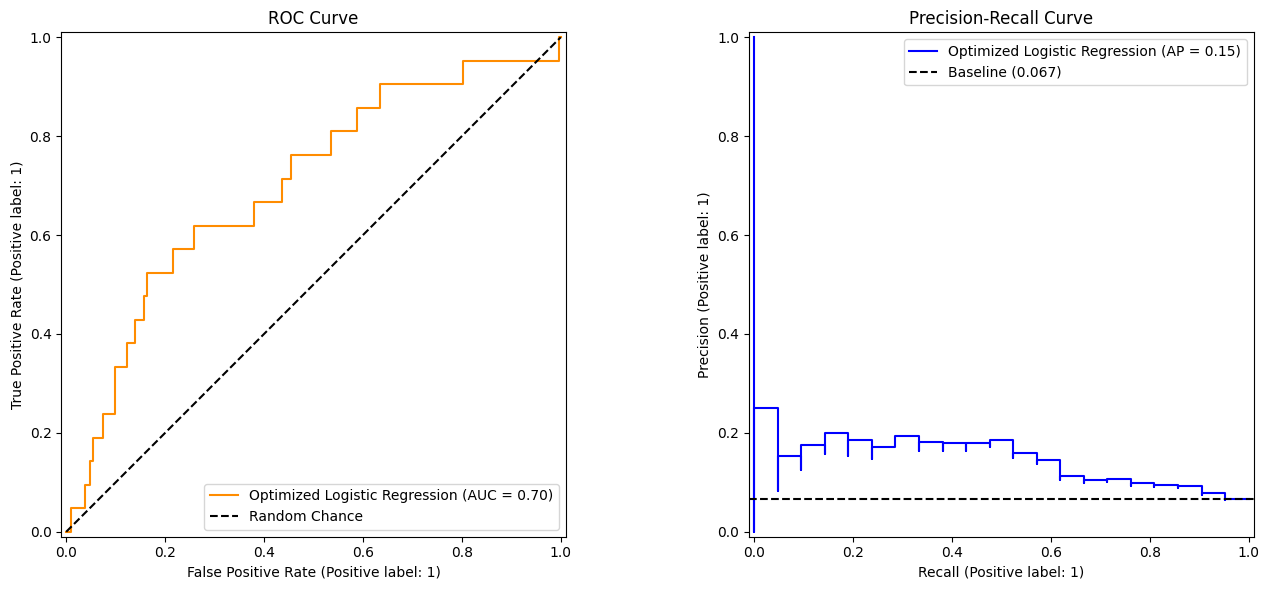

In [44]:
import matplotlib.pyplot as plt
from sklearn.metrics import RocCurveDisplay, PrecisionRecallDisplay

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# 1. ROC Curve
RocCurveDisplay.from_predictions(
    y_test,
    final_probabilities,
    name="Optimized Logistic Regression",
    ax=ax1,
    color="darkorange"
)
ax1.set_title("ROC Curve")
ax1.plot([0, 1], [0, 1], "k--", label="Random Chance")
ax1.legend()

# 2. Precision-Recall Curve
PrecisionRecallDisplay.from_predictions(
    y_test,
    final_probabilities,
    name="Optimized Logistic Regression",
    ax=ax2,
    color="blue"
)
ax2.set_title("Precision-Recall Curve")
baseline = sum(y_test == 1) / len(y_test)
ax2.axhline(baseline, color="k", linestyle="--", label=f"Baseline ({baseline:.3f})")
ax2.legend()

plt.tight_layout()
plt.show()

In [45]:
import joblib

# 1. Save the entire pipeline to a file
model_filename = "secom_defect_model.pkl"
joblib.dump(final_pipeline, model_filename)

print(f"Pipeline securely saved as: {model_filename}")

# 2. Simulate loading it in a brand new script or server
deployed_model = joblib.load(model_filename)

# 3. Test it on a single row of new factory data (using the first row of X_test)
sample_chip = X_test.iloc[[0]]
prediction = deployed_model.predict(sample_chip)
probability = deployed_model.predict_proba(sample_chip)[:, 1]

print("\nTESTING DEPLOYED MODEL:")
print("-" * 30)
print(f"Prediction: {'Fail' if prediction[0] == 1 else 'Pass'}")
print(f"Failure Probability: {probability[0]:.2%}")


Pipeline securely saved as: secom_defect_model.pkl

TESTING DEPLOYED MODEL:
------------------------------
Prediction: Pass
Failure Probability: 13.75%
